In [ ]:
low_memory=False
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline


## polynomial regression
Polynomial regression is like giving our model superpowers
-instead of just straight line we can create curves
-we can capture more complex patterns in data
-we can make better predictions for non linear relationships


# Problem setting
# when linear models fall short
- roller coaster effect: Some relationships go up and down
- growth patterns: many things start slow,speed up,then plaseau
- clinical patters:Some things repeat in cycles(like seasons)
# Example:
- height of a thrown ball over time
- stock market prices
- daily temp changes

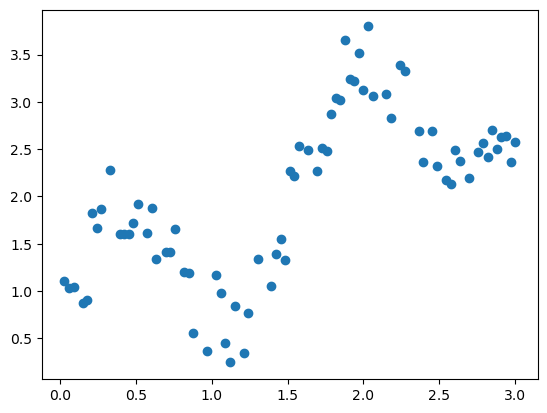

In [16]:
x=np.linspace(0,3,100)
rng = np.random.RandomState(42)
y = np.sin(4*x)+x+rng.uniform(size=len(x))
X = x[:,np.newaxis]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.25,random_state=42)
plt.scatter(X_train,y_train)
plt.show()

# Analyzing no linear pattern
Why isnt the data non linear?
- does y consistently increase/decrease as x increases
- Do you see any repeating patterns
- could a straight line capture this pattern well
# testing linear regression
fitting and checking a linear model to this data...

In [17]:
regressor = LinearRegression()
regressor.fit(X_train,y_train)
print("The r2 score:",regressor.score(X_train,y_train))
print("the mae score:",mean_absolute_error(regressor.predict(X_test),y_test))
print("the mse score:",mean_squared_error(regressor.predict(X_test),y_test))

The r2 score: 0.415082394545103
the mae score: 0.7203963843057821
the mse score: 0.7043403658672864


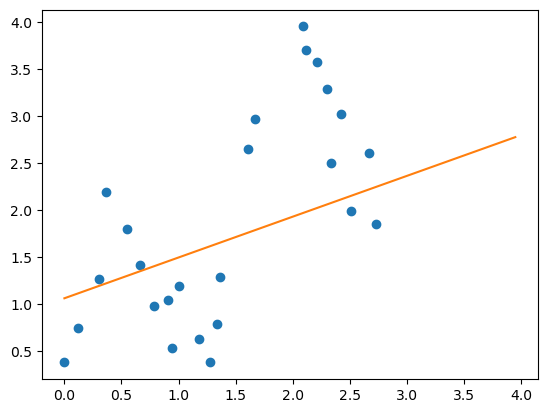

In [18]:
min_pt=X_test.min()*regressor.coef_[0]+regressor.intercept_
max_pt=X_test.max()*regressor.coef_[0]+regressor.intercept_
plt.plot(X_test,y_test,'o')
plt.plot([X_test.min(),y_test.max()],[min_pt,max_pt])
plt.show()

## understanding polynomial regression
# From lines to curves
Based on the error and the context,Heres the corrected version for the selection p laceholder
- While linear regression use straight lines,polynomial regression can create curves...
- Formula y = beta0+beta1x+beta2x^2+beta3x^3
Key concept:
# Flexibility
- linear regression(only straight lines)
- polynomial regression = curves of diff shapes
# degree of the polynomial:
- degree 1 = striaght line(same as linear regression)
- degree 2 = can make one curve(parabola)
- degree 3 = can make two curves
and so on...
# The magic number (hyperparameter):
- this is the maximun degree we allow
- higher number = more flexible curve
- too high can lead to overfitting



## Model Estimation
first polynomial model
what we will do
- start with degree 0
- see what happens
- then try diff degrees to find the best fit

In [19]:
model = LinearRegression()
pol_0 = PolynomialFeatures(degree=0)
model.fit(pol_0.fit_transform(X_train),y_train)

LinearRegression()

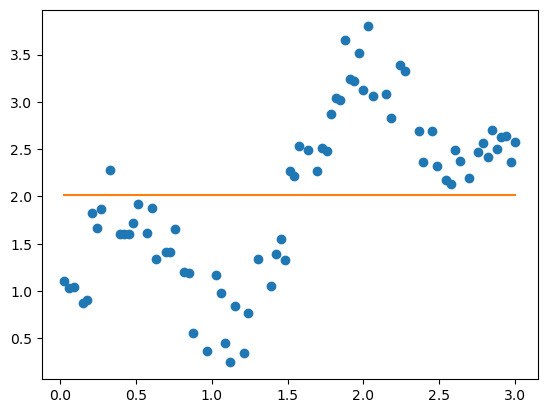

In [23]:
x=np.linspace(X_train.min(),X_train.max(),100).reshape(-1,1)
plt.plot(X_train,y_train,'o')
plt.plot(x,model.predict(pol_0.fit_transform(x)))
plt.show()

the r2 score: 0.9127806464712663


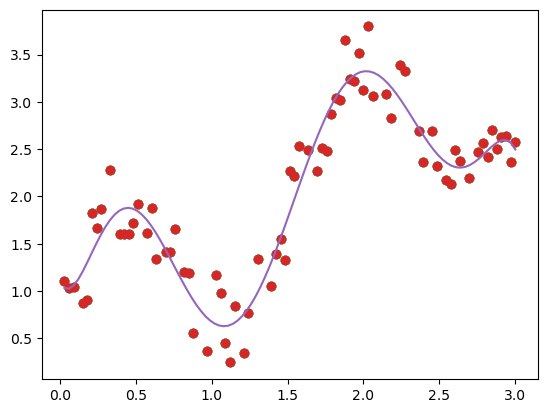

In [27]:
def pol_test(x):
    pol_exp=PolynomialFeatures(degree=x)
    model=LinearRegression()
    model.fit(pol_exp.fit_transform(X_train),y_train)
    print("the r2 score:",model.score(pol_exp.fit_transform(X_train),y_train))
    x=np.linspace(X_train.min(),X_train.max(),100).reshape(-1,1)
    plt.plot(X_train,y_train,'o')
    plt.plot(x,model.predict(pol_exp.fit_transform(x)))
    plt.show()

pol_test(7)
    

## Model Evaluation
Checking how well our model performs:
- comparing model performance by r2,mae,mse
# What to look for:
- how do scores change as degree increases?
- is there a "sweet spot"
- when do scores start getting worse?
# warnings
- very high r2 can be overfitting
- big diff between training and test scores
- erratic behave in higher degrees
# Finding balance:
- to simple = underfitting
- to complex = overfitting
- just right = good generation

In [29]:
# Calculating the marics
for x in range(1,41):
    pol_exp = PolynomialFeatures(degree=x)
    model = LinearRegression()
    model.fit(pol_exp.fit_transform(X_train),y_train)
    print("Evaluations for the model where x equals",x)
    print("the r2 score:",model.score(pol_exp.fit_transform(X_test),y_test))
    print("the mae:",mean_absolute_error(model.predict(pol_exp.fit_transform(X_test)),y_test))
    print("the mse:",mean_squared_error(model.predict(pol_exp.fit_transform(X_test)),y_test))

Evaluations for the model where x equals 1
the r2 score: 0.41067297381418255
the mae: 0.7203963843057821
the mse: 0.7043403658672862
Evaluations for the model where x equals 2
the r2 score: 0.4106990570496194
the mae: 0.7183502207943911
the mse: 0.7043091922153506
Evaluations for the model where x equals 3
the r2 score: 0.5280182301969966
the mae: 0.6374872097492896
the mse: 0.5640939540432992
Evaluations for the model where x equals 4
the r2 score: 0.5735851595235388
the mae: 0.6175923410600807
the mse: 0.5096341613522611
Evaluations for the model where x equals 5
the r2 score: 0.8463569260655377
the mae: 0.38190863357031396
the mse: 0.18362812852545532
Evaluations for the model where x equals 6
the r2 score: 0.8525232800134689
the mae: 0.3712486461489038
the mse: 0.1762583460400622
Evaluations for the model where x equals 7
the r2 score: 0.8670815754380163
the mae: 0.3584684388692707
the mse: 0.158858846831457
Evaluations for the model where x equals 8
the r2 score: 0.871457765049346